
# 23 — Scorer × Generator Family Diagonal

## Question

Does generated text contain **family-specific dependency structure** that is preferentially
visible to an autoregressive scorer from the corresponding model family?

Let \(g\) denote the generator family and \(s\) the independent scorer family. For each
completed generation \(x_{i,g}\) from matched prompt \(i\), compute

\[
L_{i,s,g}(k)
=
-\frac{1}{|T|}
\sum_{t\in T}
\log q_s(x_t\mid x_{t-k:t-1})
\]

at the six logarithmically spaced contexts

\[
k\in\{8,16,32,64,128,256\}.
\]

Define

\[
U_{i,s,g}(k)
=
L_{i,s,g}(8)-L_{i,s,g}(k).
\]

This gives a matched tensor

\[
\boxed{
\text{prompt}\times\text{scorer family}\times
\text{generator family}\times\text{context length}.
}
\]

The central hypothesis is a **diagonal advantage**:

\[
\text{home-family scorer}
\quad\text{vs}\quad
\text{non-home scorers}.
\]

Importantly, the generator and scorer are *not the exact same checkpoint*. Generators are
instruction/post-trained models while scorers are their base-family counterparts. A
diagonal effect therefore tests family alignment rather than the trivial fact that a
model assigns high probability to samples drawn from its exact own distribution.

## Six public small-model families

| Family | Generator | Frozen scorer |
|---|---|---|
| Qwen | `Qwen/Qwen2.5-0.5B-Instruct` | `Qwen/Qwen2.5-0.5B` |
| SmolLM2 | `HuggingFaceTB/SmolLM2-360M-Instruct` | `HuggingFaceTB/SmolLM2-360M` |
| OLMo2 | `allenai/OLMo-2-0425-1B-Instruct` | `allenai/OLMo-2-0425-1B` |
| StableLM2 | `stabilityai/stablelm-2-zephyr-1_6b` | `stabilityai/stablelm-2-1_6b` |
| TinyLlama | `TinyLlama/TinyLlama-1.1B-Chat-v1.0` | `TinyLlama/TinyLlama-1.1B-intermediate-step-1431k-3T` |
| Falcon3 | `tiiuae/Falcon3-1B-Instruct` | `tiiuae/Falcon3-1B-Base` |

All models fit comfortably one-at-a-time on an 8 GB RTX 2000 Ada. No two models are
resident on GPU simultaneously.

## Three increasingly nontrivial diagonal tests

### 1. Raw-loss diagonal — sanity check

Does the home-family base scorer simply assign lower loss to its corresponding
instruction model's outputs?

This can arise from tokenizer, architecture, pretraining distribution, and lineage, so
it is *not* the main scientific claim.

### 2. Context-response diagonal

After removing scorer/prompt scale, does the home-family scorer obtain unusually large
long-range context benefit

\[
U(128),\quad U(256)
\]

from its corresponding generator?

A positive diagonal here is more interesting because \(U(k)\) removes the scorer's
short-context loss baseline.

### 3. Generator-identification diagonal — primary

For each scorer \(s\), train a source-grouped classifier to identify the six generator
families using either

\[
(L_8,L_{16},L_{32},L_{64},L_{128},L_{256})
\]

or the context-gain shape

\[
(U_{16},U_{32},U_{64},U_{128},U_{256}).
\]

Let

\[
A_{s,g}
\]

be one-vs-rest AUROC for recognizing generator \(g\) using scorer \(s\)'s context
response. The primary diagonal statistic is

\[
D_g
=
A_{g,g}
-
\frac{1}{S-1}
\sum_{s\neq g}A_{s,g}.
\]

A systematic \(D_g>0\), especially for the \(U\)-shape representation, would indicate
that family-specific dependency fingerprints are preferentially exposed by the
corresponding scorer family.

## Interpretation guardrail

A diagonal in raw \(L_k\) alone is unsurprising.

The scientifically interesting outcomes are:

- diagonal enrichment in \(U\)-shape generator identification;
- diagonal enrichment surviving within-scorer/prompt standardization;
- structure stronger at \(U(128)\) or \(U(256)\) than at \(U(32)\);
- blocks or clusters among related scorer/generator families.

A null diagonal is also informative: it would suggest that generator-family dependency
fingerprints, if present, are broadly readable rather than home-scorer-specific.


In [1]:

from pathlib import Path
from itertools import combinations
import gc
import inspect
import json
import time
import warnings

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from transformers import (
    AutoConfig,
    AutoTokenizer,
    AutoModelForCausalLM,
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd

DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
GENERATED = DATA / "generated"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
GENERATED.mkdir(parents=True, exist_ok=True)

ESSAY_PATH = DATA / "raw" / "ghostbuster_essays.parquet"
assert ESSAY_PATH.exists(), ESSAY_PATH

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("ROOT:", ROOT)
print("device:", DEVICE)

if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    print("GPU:", p.name)
    print("VRAM GiB:", round(p.total_memory / 2**30, 2))


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
device: cuda
GPU: NVIDIA RTX 2000 Ada Generation Laptop GPU
VRAM GiB: 7.62


In [2]:

# ------------------------------------------------------------------
# FROZEN EXPERIMENT CONFIGURATION
# ------------------------------------------------------------------

FAMILIES = {
    "Qwen": {
        "generator": "Qwen/Qwen2.5-0.5B-Instruct",
        "scorer": "Qwen/Qwen2.5-0.5B",
    },
    "SmolLM2": {
        "generator": "HuggingFaceTB/SmolLM2-360M-Instruct",
        "scorer": "HuggingFaceTB/SmolLM2-360M",
    },
    "OLMo2": {
        "generator": "allenai/OLMo-2-0425-1B-Instruct",
        "scorer": "allenai/OLMo-2-0425-1B",
    },
    "StableLM2": {
        "generator": "stabilityai/stablelm-2-zephyr-1_6b",
        "scorer": "stabilityai/stablelm-2-1_6b",
    },
    "TinyLlama": {
        "generator": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
        "scorer": "TinyLlama/TinyLlama-1.1B-intermediate-step-1431k-3T",
    },
    "Falcon3": {
        "generator": "tiiuae/Falcon3-1B-Instruct",
        "scorer": "tiiuae/Falcon3-1B-Base",
    },
}

FAMILY_ORDER = list(FAMILIES)

# Compute-bounded default.
N_PROMPTS = 48
PROMPT_SEED = 2301

# Use a short human seed passage to match semantic/topic content.
SEED_WORDS = 48

# Generate enough text to remain >=384 tokens under all six scorer tokenizers.
MIN_NEW_TOKENS = 480
MAX_NEW_TOKENS = 520
GEN_TEMPERATURE = 0.8
GEN_TOP_P = 0.95
GEN_SEED = 2302

# SL6 measurement.
PREFIX_LEN = 384
CONTEXT_LENGTHS = [8, 16, 32, 64, 128, 256]
N_CONTEXT_TARGETS = 8

# One model at a time. Generation batch is deliberately 1.
SCORING_BATCH_SIZE = 8
SCORING_FALLBACK_BATCH_SIZE = 2

N_SPLITS = 20
TEST_FRAC = 0.25
SPLIT_SEED = 2303

N_BOOT = 2000
BOOT_SEED = 2304

PROMPT_MANIFEST = RESULTS / "sxg23_prompt_manifest.parquet"
GEN_ALL_PATH = GENERATED / "sxg23_generations.parquet"
ELIGIBLE_PATH = RESULTS / "sxg23_joint_eligible_generations.parquet"
SCORES_PATH = RESULTS / "sxg23_sl6_scores.parquet"

print(json.dumps(FAMILIES, indent=2))


{
  "Qwen": {
    "generator": "Qwen/Qwen2.5-0.5B-Instruct",
    "scorer": "Qwen/Qwen2.5-0.5B"
  },
  "SmolLM2": {
    "generator": "HuggingFaceTB/SmolLM2-360M-Instruct",
    "scorer": "HuggingFaceTB/SmolLM2-360M"
  },
  "OLMo2": {
    "generator": "allenai/OLMo-2-0425-1B-Instruct",
    "scorer": "allenai/OLMo-2-0425-1B"
  },
  "StableLM2": {
    "generator": "stabilityai/stablelm-2-zephyr-1_6b",
    "scorer": "stabilityai/stablelm-2-1_6b"
  },
  "TinyLlama": {
    "generator": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    "scorer": "TinyLlama/TinyLlama-1.1B-intermediate-step-1431k-3T"
  },
  "Falcon3": {
    "generator": "tiiuae/Falcon3-1B-Instruct",
    "scorer": "tiiuae/Falcon3-1B-Base"
  }
}



## 1. Lightweight model-access audit

This cell downloads only configuration/tokenizer metadata. Run it before any expensive
generation.

If one model repository is unavailable, stop here rather than discovering the problem
after several hours of compute.


In [3]:

audit_rows = []

for family, cfg in FAMILIES.items():
    for role in ["generator", "scorer"]:
        model_id = cfg[role]

        print(f"{family:10s} {role:9s} {model_id}")

        try:
            conf = AutoConfig.from_pretrained(
                model_id,
                trust_remote_code=True,
            )
            tok = AutoTokenizer.from_pretrained(
                model_id,
                trust_remote_code=True,
                use_fast=True,
            )

            audit_rows.append({
                "family": family,
                "role": role,
                "model_id": model_id,
                "ok": True,
                "model_type": getattr(conf, "model_type", None),
                "vocab_size": getattr(conf, "vocab_size", None),
                "has_chat_template": bool(
                    getattr(tok, "chat_template", None)
                ),
            })

            del conf, tok

        except Exception as e:
            audit_rows.append({
                "family": family,
                "role": role,
                "model_id": model_id,
                "ok": False,
                "error": repr(e),
            })

    gc.collect()

model_audit = pd.DataFrame(audit_rows)
display(model_audit)

assert model_audit["ok"].all(), (
    "At least one model is unavailable. Resolve that before continuing."
)


Qwen       generator Qwen/Qwen2.5-0.5B-Instruct


Qwen       scorer    Qwen/Qwen2.5-0.5B
SmolLM2    generator HuggingFaceTB/SmolLM2-360M-Instruct
SmolLM2    scorer    HuggingFaceTB/SmolLM2-360M
OLMo2      generator allenai/OLMo-2-0425-1B-Instruct
OLMo2      scorer    allenai/OLMo-2-0425-1B
StableLM2  generator stabilityai/stablelm-2-zephyr-1_6b
StableLM2  scorer    stabilityai/stablelm-2-1_6b
TinyLlama  generator TinyLlama/TinyLlama-1.1B-Chat-v1.0
TinyLlama  scorer    TinyLlama/TinyLlama-1.1B-intermediate-step-1431k-3T
Falcon3    generator tiiuae/Falcon3-1B-Instruct
Falcon3    scorer    tiiuae/Falcon3-1B-Base


,family,role,model_id,ok,model_type,vocab_size,has_chat_template
0,Qwen,generator,Qwen/Qwen2.5-0.5B-Instruct,True,qwen2,151936,True
1,Qwen,scorer,Qwen/Qwen2.5-0.5B,True,qwen2,151936,True
2,SmolLM2,generator,HuggingFaceTB/SmolLM2-360M-Instruct,True,llama,49152,True
3,SmolLM2,scorer,HuggingFaceTB/SmolLM2-360M,True,llama,49152,False
4,OLMo2,generator,allenai/OLMo-2-0425-1B-Instruct,True,olmo2,100352,True
5,OLMo2,scorer,allenai/OLMo-2-0425-1B,True,olmo2,100352,False
6,StableLM2,generator,stabilityai/stablelm-2-zephyr-1_6b,True,stablelm,100352,True
7,StableLM2,scorer,stabilityai/stablelm-2-1_6b,True,stablelm,100352,False
8,TinyLlama,generator,TinyLlama/TinyLlama-1.1B-Chat-v1.0,True,llama,32000,True
9,TinyLlama,scorer,TinyLlama/TinyLlama-1.1B-intermediate-step-143...,True,llama,32000,False



## 2. Build 48 matched continuation prompts

We use human Ghostbuster essays only as **topic/semantic seeds**.

For each selected essay ID, take the first 48 whitespace-separated words and ask every
generator to continue the passage in coherent prose. The generated continuation itself
is the only text later scored.

This gives exact prompt matching across all six generator families without relying on
their original training/evaluation prompt formats.


In [4]:

raw = pd.read_parquet(ESSAY_PATH).copy()
raw["group_id"] = raw["group_id"].astype(str)

human = (
    raw[raw["generator"] == "human"]
    [["group_id", "text"]]
    .drop_duplicates("group_id")
    .copy()
)

human["seed_text"] = human["text"].map(
    lambda x: " ".join(str(x).split()[:SEED_WORDS])
)

human = human[
    human["seed_text"].str.split().map(len) >= SEED_WORDS
].copy()

rng = np.random.RandomState(PROMPT_SEED)

chosen = np.sort(
    rng.choice(
        human["group_id"].to_numpy(),
        size=N_PROMPTS,
        replace=False,
    )
)

prompts = (
    human[human["group_id"].isin(chosen)]
    [["group_id", "seed_text"]]
    .sort_values("group_id")
    .reset_index(drop=True)
)

prompts["prompt_index"] = np.arange(len(prompts))
prompts["prompt_seed"] = PROMPT_SEED

prompts.to_parquet(
    PROMPT_MANIFEST,
    index=False,
)

print("prompts:", len(prompts))
display(prompts.head())
print("saved:", PROMPT_MANIFEST)


prompts: 48


,group_id,seed_text,prompt_index,prompt_seed
0,100,International labor laws prohibit making emplo...,0,2301
1,117,Most writers rely on their stories’ pivotal po...,1,2301
2,165,Chronic pain is still considered to be an extr...,2,2301
3,166,Introduction Descartes’ philosophy is called d...,3,2301
4,170,"In order to prevent heart disease, cancer, and...",4,2301


saved: ../results/sxg23_prompt_manifest.parquet



## 3. Generate matched outputs sequentially

Every family is generated in a separate model-loading pass. Checkpoints are saved after
every four prompts, so interruption does not lose completed work.

Generation uses the model's native chat template where available.

The prompt is:

> Continue the supplied passage in coherent prose. Write only the continuation and do
> not discuss the instruction.

The scored text is only the newly generated continuation, never the chat template or
seed passage.


In [5]:

def family_slug(x):
    return x.lower().replace("-", "_").replace(".", "")


def generation_path(family):
    return GENERATED / f"sxg23_generation_{family_slug(family)}.parquet"


def make_instruction(seed_text):
    return (
        "Continue the following passage in coherent English prose. "
        "Write only the continuation. Do not explain the task, mention the instruction, "
        "or repeat the passage verbatim. Maintain a natural essay or narrative style.\n\n"
        f"PASSAGE:\n{seed_text}"
    )


def build_generation_inputs(tokenizer, seed_text):
    instruction = make_instruction(seed_text)

    if getattr(tokenizer, "chat_template", None):
        messages = [
            {
                "role": "user",
                "content": instruction,
            }
        ]

        rendered = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )

        return tokenizer(
            rendered,
            return_tensors="pt",
            add_special_tokens=False,
        )

    # Fallback for any model lacking a chat template.
    return tokenizer(
        instruction + "\n\nCONTINUATION:\n",
        return_tensors="pt",
        add_special_tokens=True,
    )


for family_index, (family, cfg) in enumerate(FAMILIES.items()):
    path = generation_path(family)

    print("\n" + "=" * 76)
    print("GENERATOR FAMILY:", family)
    print(cfg["generator"])
    print("checkpoint:", path)

    if path.exists():
        done = pd.read_parquet(path)
        done_ids = set(done["group_id"].astype(str))
        print("existing generations:", len(done))
    else:
        done = pd.DataFrame()
        done_ids = set()

    remaining = prompts[
        ~prompts["group_id"].isin(done_ids)
    ].copy()

    if len(remaining) == 0:
        print("already complete")
        continue

    tokenizer = AutoTokenizer.from_pretrained(
        cfg["generator"],
        trust_remote_code=True,
        use_fast=True,
    )

    dtype = (
        torch.float16
        if DEVICE == "cuda"
        else torch.float32
    )

    model = AutoModelForCausalLM.from_pretrained(
        cfg["generator"],
        trust_remote_code=True,
        torch_dtype=dtype,
    ).to(DEVICE)

    model.eval()

    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token

    if DEVICE == "cuda":
        torch.cuda.empty_cache()
        print(
            "allocated GiB:",
            round(torch.cuda.memory_allocated() / 2**30, 3),
        )

    new_rows = []
    t0 = time.time()

    for local_n, r in enumerate(
        tqdm(
            remaining.itertuples(index=False),
            total=len(remaining),
            desc=f"generate {family}",
        ),
        start=1,
    ):
        inputs = build_generation_inputs(
            tokenizer,
            r.seed_text,
        )

        input_ids = inputs["input_ids"].to(DEVICE)
        attention_mask = inputs.get("attention_mask")

        if attention_mask is not None:
            attention_mask = attention_mask.to(DEVICE)

        # Deterministic per prompt/family seed.
        seed = (
            GEN_SEED
            + family_index * 100_000
            + int(r.prompt_index)
        )

        torch.manual_seed(seed)
        if DEVICE == "cuda":
            torch.cuda.manual_seed_all(seed)

        kwargs = {
            "input_ids": input_ids,
            "do_sample": True,
            "temperature": GEN_TEMPERATURE,
            "top_p": GEN_TOP_P,
            "min_new_tokens": MIN_NEW_TOKENS,
            "max_new_tokens": MAX_NEW_TOKENS,
            "pad_token_id": tokenizer.pad_token_id,
        }

        if attention_mask is not None:
            kwargs["attention_mask"] = attention_mask

        with torch.inference_mode():
            out = model.generate(**kwargs)

        new_ids = out[0, input_ids.shape[1]:]

        generated_text = tokenizer.decode(
            new_ids,
            skip_special_tokens=True,
        ).strip()

        new_rows.append({
            "group_id": str(r.group_id),
            "prompt_index": int(r.prompt_index),
            "generator_family": family,
            "generator_model": cfg["generator"],
            "generation_seed": seed,
            "seed_text": r.seed_text,
            "text": generated_text,
            "n_generator_tokens": int(len(new_ids)),
            "n_chars": len(generated_text),
        })

        del inputs, input_ids, attention_mask, out, new_ids

        if (
            local_n % 4 == 0
            or local_n == len(remaining)
        ):
            block = pd.DataFrame(new_rows)

            merged = pd.concat(
                [done, block],
                ignore_index=True,
            )

            merged = (
                merged
                .drop_duplicates(
                    subset=["group_id"],
                    keep="last",
                )
                .sort_values("group_id")
                .reset_index(drop=True)
            )

            merged.to_parquet(
                path,
                index=False,
            )

            done = merged
            new_rows = []

    print(
        family,
        "minutes:",
        round((time.time() - t0) / 60, 1),
    )

    del model, tokenizer
    gc.collect()

    if DEVICE == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
        print(
            "allocated after unload GiB:",
            round(torch.cuda.memory_allocated() / 2**30, 3),
        )



GENERATOR FAMILY: Qwen
Qwen/Qwen2.5-0.5B-Instruct
checkpoint: ../data/generated/sxg23_generation_qwen.parquet


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 290/290 [00:00<00:00, 3281.15it/s]


allocated GiB: 0.928


generate Qwen: 100%|████████████████████████████████████████████████████████████████████████████████████| 48/48 [05:16<00:00,  6.60s/it]


Qwen minutes: 5.3
allocated after unload GiB: 0.008

GENERATOR FAMILY: SmolLM2
HuggingFaceTB/SmolLM2-360M-Instruct
checkpoint: ../data/generated/sxg23_generation_smollm2.parquet


...

TinyLlama minutes: 5.5
allocated after unload GiB: 0.008

GENERATOR FAMILY: Falcon3
tiiuae/Falcon3-1B-Instruct
checkpoint: ../data/generated/sxg23_generation_falcon3.parquet


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 607.09it/s]


allocated GiB: 3.117


generate Falcon3: 100%|█████████████████████████████████████████████████████████████████████████████████| 48/48 [06:51<00:00,  8.57s/it]


Falcon3 minutes: 6.9
allocated after unload GiB: 0.008


In [6]:

# Combine all six generator checkpoints.

generation_parts = []

for family in FAMILY_ORDER:
    path = generation_path(family)
    assert path.exists(), path

    q = pd.read_parquet(path).copy()
    q = q[
        q["group_id"].isin(prompts["group_id"])
    ]

    assert len(q) == N_PROMPTS, (
        family,
        len(q),
        N_PROMPTS,
    )

    generation_parts.append(q)

generations = pd.concat(
    generation_parts,
    ignore_index=True,
)

generations.to_parquet(
    GEN_ALL_PATH,
    index=False,
)

audit = (
    generations
    .groupby("generator_family")
    .agg(
        n=("group_id", "size"),
        mean_gen_tokens=("n_generator_tokens", "mean"),
        mean_chars=("n_chars", "mean"),
    )
    .reindex(FAMILY_ORDER)
)

display(audit)
print("saved:", GEN_ALL_PATH)


,n,mean_gen_tokens,mean_chars
generator_family,,,
Qwen,48,505.937500,3040.166667
SmolLM2,48,509.229167,2741.604167
OLMo2,48,506.604167,2915.041667
StableLM2,48,503.854167,2744.708333
TinyLlama,48,511.604167,2352.833333
Falcon3,48,507.437500,2872.687500


saved: ../data/generated/sxg23_generations.parquet



## 4. Joint scorer-token eligibility + tokenizer diagnostic

A prompt is retained only if **every one of its six generated continuations** contains at
least 384 tokens under **every one of the six scorer tokenizers**.

This ensures the 6×6 matrix uses exactly the same prompt set.

We also save token counts because a home-family raw-loss advantage could partly reflect
tokenizer compatibility. A context-response diagonal is more interesting if it is not
simply mirrored by a tokenizer-length diagonal.


In [7]:

elig = generations[
    [
        "group_id",
        "generator_family",
        "text",
        "n_chars",
    ]
].copy()

token_count_rows = []

for scorer_family, cfg in FAMILIES.items():
    print("tokenizer:", scorer_family)

    tok = AutoTokenizer.from_pretrained(
        cfg["scorer"],
        trust_remote_code=True,
        use_fast=True,
    )

    for r in tqdm(
        elig.itertuples(index=False),
        total=len(elig),
        leave=False,
    ):
        ids = tok(
            str(r.text),
            add_special_tokens=False,
            truncation=False,
        )["input_ids"]

        token_count_rows.append({
            "group_id": r.group_id,
            "generator_family": r.generator_family,
            "scorer_family": scorer_family,
            "n_scorer_tokens": len(ids),
            "n_chars": r.n_chars,
            "tokens_per_1k_chars":
                1000.0 * len(ids) / max(r.n_chars, 1),
        })

    del tok
    gc.collect()

token_counts = pd.DataFrame(token_count_rows)

elig_flag = (
    token_counts
    .assign(
        eligible=lambda d:
            d["n_scorer_tokens"] >= PREFIX_LEN
    )
    .groupby(
        ["group_id", "generator_family"]
    )["eligible"]
    .all()
    .reset_index()
)

prompt_ok = (
    elig_flag
    .groupby("group_id")["eligible"]
    .all()
)

eligible_groups = np.array(
    sorted(prompt_ok.index[prompt_ok])
)

eligible_generations = (
    generations[
        generations["group_id"].isin(
            eligible_groups
        )
    ]
    .copy()
    .sort_values(
        ["group_id", "generator_family"]
    )
    .reset_index(drop=True)
)

eligible_generations.to_parquet(
    ELIGIBLE_PATH,
    index=False,
)

print(
    "jointly eligible prompts:",
    len(eligible_groups),
    "/",
    N_PROMPTS,
)

assert len(eligible_groups) >= 32, (
    "Too many prompts failed joint eligibility. "
    "Increase generation length before scoring."
)

display(
    token_counts
    .groupby(
        ["scorer_family", "generator_family"]
    )["tokens_per_1k_chars"]
    .mean()
    .unstack()
    .reindex(
        index=FAMILY_ORDER,
        columns=FAMILY_ORDER,
    )
)

print("saved:", ELIGIBLE_PATH)


tokenizer: Qwen


tokenizer: SmolLM2


tokenizer: OLMo2


tokenizer: StableLM2


tokenizer: TinyLlama


tokenizer: Falcon3


jointly eligible prompts: 46 / 48


generator_family,Qwen,SmolLM2,OLMo2,StableLM2,TinyLlama,Falcon3
scorer_family,,,,,,
Qwen,167.008359,182.986001,174.640439,183.349057,184.196846,176.699879
SmolLM2,167.160487,186.875954,177.397300,187.970211,189.772155,177.914405
OLMo2,166.228775,182.319072,174.052986,183.723168,183.613410,175.521021
StableLM2,167.020443,182.986001,174.647395,184.958056,184.893972,176.699879
TinyLlama,204.536882,211.285214,211.386132,220.371536,219.024143,216.251285
Falcon3,166.647744,184.833984,177.101674,187.280951,188.441439,177.561424


saved: ../results/sxg23_joint_eligible_generations.parquet



## 5. SL6 scoring — expensive step

This evaluates every jointly eligible generation with every scorer family.

With 48 prompts and no eligibility loss:

\[
48\times6\times6=1728
\]

scorer-document combinations.

Each combination uses six context lengths and eight fixed target positions.

This is similar in total scoring scale to notebook 22, but with SL6 rather than four
contexts. Scorers are loaded and unloaded sequentially.

For models without `logits_to_keep`, batch size automatically falls to 2 to avoid
materializing a large full-sequence vocabulary tensor on the 8 GB GPU.


In [8]:

def scorer_slug(x):
    return (
        x.lower()
        .replace("-", "_")
        .replace(".", "")
    )


def score_checkpoint_path(family):
    return RESULTS / f"sxg23_scores_{scorer_slug(family)}.parquet"


@torch.inference_mode()
def score_one_text(
    text,
    tokenizer,
    model,
    batch_size,
    supports_logits_to_keep,
):
    ids = tokenizer(
        str(text),
        add_special_tokens=False,
        return_tensors="pt",
        truncation=True,
        max_length=PREFIX_LEN,
    )["input_ids"][0]

    if len(ids) < PREFIX_LEN:
        return None

    ids = ids[:PREFIX_LEN]

    max_k = max(CONTEXT_LENGTHS)

    positions = np.linspace(
        max_k,
        len(ids) - 1,
        N_CONTEXT_TARGETS,
        dtype=int,
    )

    positions = np.unique(positions)

    if len(positions) != N_CONTEXT_TARGETS:
        raise RuntimeError(
            "Target-position rounding produced duplicates."
        )

    ans = {}

    for k in CONTEXT_LENGTHS:
        sequences = torch.stack([
            ids[pos-k:pos]
            for pos in positions
        ])

        targets = torch.stack([
            ids[pos]
            for pos in positions
        ])

        total_nll = 0.0
        total_count = 0

        for start in range(
            0,
            len(sequences),
            batch_size,
        ):
            x = sequences[
                start:start + batch_size
            ].to(DEVICE)

            y = targets[
                start:start + batch_size
            ].to(DEVICE)

            kwargs = {"input_ids": x}

            if supports_logits_to_keep:
                kwargs["logits_to_keep"] = 1

            out = model(**kwargs)

            logits = out.logits[:, -1, :].float()

            log_probs = torch.log_softmax(
                logits,
                dim=-1,
            )

            idx = torch.arange(
                len(y),
                device=DEVICE,
            )

            nll = -log_probs[idx, y]

            total_nll += float(nll.sum())
            total_count += len(y)

            del x, y, out, logits, log_probs, nll

        ans[f"L_{k}"] = total_nll / total_count

    for k in CONTEXT_LENGTHS[1:]:
        ans[f"U_{k}"] = (
            ans["L_8"] - ans[f"L_{k}"]
        )

    return ans


In [9]:

for scorer_family, cfg in FAMILIES.items():
    path = score_checkpoint_path(
        scorer_family
    )

    print("\n" + "=" * 76)
    print("SCORER FAMILY:", scorer_family)
    print(cfg["scorer"])
    print("checkpoint:", path)

    if path.exists():
        done = pd.read_parquet(path)
        done_keys = set(
            zip(
                done["group_id"].astype(str),
                done["generator_family"],
            )
        )
        print("existing:", len(done))
    else:
        done = pd.DataFrame()
        done_keys = set()

    remaining = eligible_generations[
        [
            (str(gid), fam) not in done_keys
            for gid, fam in zip(
                eligible_generations["group_id"],
                eligible_generations["generator_family"],
            )
        ]
    ].copy()

    if len(remaining) == 0:
        print("already complete")
        continue

    tokenizer = AutoTokenizer.from_pretrained(
        cfg["scorer"],
        trust_remote_code=True,
        use_fast=True,
    )

    dtype = (
        torch.float16
        if DEVICE == "cuda"
        else torch.float32
    )

    model = AutoModelForCausalLM.from_pretrained(
        cfg["scorer"],
        trust_remote_code=True,
        torch_dtype=dtype,
    ).to(DEVICE)

    model.eval()

    sig = inspect.signature(model.forward)

    supports_logits_to_keep = (
        "logits_to_keep" in sig.parameters
    )

    batch_size = (
        SCORING_BATCH_SIZE
        if supports_logits_to_keep
        else SCORING_FALLBACK_BATCH_SIZE
    )

    print(
        "logits_to_keep:",
        supports_logits_to_keep,
        "| scoring batch:",
        batch_size,
    )

    if DEVICE == "cuda":
        torch.cuda.empty_cache()
        print(
            "allocated GiB:",
            round(torch.cuda.memory_allocated() / 2**30, 3),
        )

    new_rows = []
    t0 = time.time()

    for n, r in enumerate(
        tqdm(
            remaining.itertuples(index=False),
            total=len(remaining),
            desc=f"score {scorer_family}",
        ),
        start=1,
    ):
        feats = score_one_text(
            r.text,
            tokenizer=tokenizer,
            model=model,
            batch_size=batch_size,
            supports_logits_to_keep=supports_logits_to_keep,
        )

        if feats is None:
            raise RuntimeError(
                f"Unexpected eligibility failure: "
                f"{r.group_id} / {r.generator_family}"
            )

        new_rows.append({
            "group_id": str(r.group_id),
            "prompt_index": int(r.prompt_index),
            "generator_family": r.generator_family,
            "generator_model": r.generator_model,
            "scorer_family": scorer_family,
            "scorer_model": cfg["scorer"],
            **feats,
        })

        if (
            n % 20 == 0
            or n == len(remaining)
        ):
            block = pd.DataFrame(new_rows)

            merged = pd.concat(
                [done, block],
                ignore_index=True,
            )

            merged = (
                merged
                .drop_duplicates(
                    subset=[
                        "group_id",
                        "generator_family",
                    ],
                    keep="last",
                )
                .sort_values(
                    ["group_id", "generator_family"]
                )
                .reset_index(drop=True)
            )

            merged.to_parquet(
                path,
                index=False,
            )

            done = merged
            new_rows = []

    print(
        "minutes:",
        round((time.time() - t0) / 60, 1),
    )

    del model, tokenizer
    gc.collect()

    if DEVICE == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

        print(
            "allocated after unload GiB:",
            round(torch.cuda.memory_allocated() / 2**30, 3),
        )



SCORER FAMILY: Qwen
Qwen/Qwen2.5-0.5B
checkpoint: ../results/sxg23_scores_qwen.parquet


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 290/290 [00:00<00:00, 3160.40it/s]


logits_to_keep: True | scoring batch: 8
allocated GiB: 0.936


score Qwen: 100%|█████████████████████████████████████████████████████████████████████████████████████| 276/276 [00:55<00:00,  4.98it/s]


minutes: 0.9
allocated after unload GiB: 0.008

SCORER FAMILY: SmolLM2
HuggingFaceTB/SmolLM2-360M
checkpoint: ../results/sxg23_scores_smollm2.parquet


...

minutes: 2.0
allocated after unload GiB: 0.008

SCORER FAMILY: Falcon3
tiiuae/Falcon3-1B-Base
checkpoint: ../results/sxg23_scores_falcon3.parquet


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 599.93it/s]


logits_to_keep: True | scoring batch: 8
allocated GiB: 3.117


score Falcon3: 100%|██████████████████████████████████████████████████████████████████████████████████| 276/276 [02:17<00:00,  2.01it/s]


minutes: 2.3
allocated after unload GiB: 0.008


In [10]:

# Combine scorer checkpoints.

score_parts = []

for scorer_family in FAMILY_ORDER:
    path = score_checkpoint_path(
        scorer_family
    )

    assert path.exists(), path

    q = pd.read_parquet(path).copy()

    q = q[
        q["group_id"].isin(
            eligible_groups
        )
    ]

    score_parts.append(q)

scores = pd.concat(
    score_parts,
    ignore_index=True,
)

expected = (
    len(eligible_groups)
    * len(FAMILY_ORDER)
    * len(FAMILY_ORDER)
)

print("rows:", len(scores), "/", expected)
assert len(scores) == expected

scores.to_parquet(
    SCORES_PATH,
    index=False,
)

audit = (
    scores
    .groupby(
        ["scorer_family", "generator_family"]
    )
    .size()
    .unstack()
    .reindex(
        index=FAMILY_ORDER,
        columns=FAMILY_ORDER,
    )
)

display(audit)
print("saved:", SCORES_PATH)


rows: 1656 / 1656


generator_family,Qwen,SmolLM2,OLMo2,StableLM2,TinyLlama,Falcon3
scorer_family,,,,,,
Qwen,46,46,46,46,46,46
SmolLM2,46,46,46,46,46,46
OLMo2,46,46,46,46,46,46
StableLM2,46,46,46,46,46,46
TinyLlama,46,46,46,46,46,46
Falcon3,46,46,46,46,46,46


saved: ../results/sxg23_sl6_scores.parquet



# Analysis I — mean 6×6 response matrices

First inspect the raw cell means.

A raw-loss diagonal is a sanity check. The more important matrices are \(U(128)\) and
\(U(256)\).


In [11]:

RAW_L = [f"L_{k}" for k in CONTEXT_LENGTHS]
U_COLS = [
    f"U_{k}"
    for k in CONTEXT_LENGTHS[1:]
]

cell_means = (
    scores
    .groupby(
        ["scorer_family", "generator_family"]
    )[RAW_L + U_COLS]
    .mean()
)

for metric in [
    "L_256",
    "U_32",
    "U_128",
    "U_256",
]:
    print("\n", metric)

    display(
        cell_means[metric]
        .unstack()
        .reindex(
            index=FAMILY_ORDER,
            columns=FAMILY_ORDER,
        )
    )



 L_256


generator_family,Qwen,SmolLM2,OLMo2,StableLM2,TinyLlama,Falcon3
scorer_family,,,,,,
Qwen,1.650534,1.198269,1.779499,1.751172,1.293264,1.557548
SmolLM2,1.930083,1.093507,1.736136,1.492289,1.316355,1.655579
OLMo2,2.192667,1.382516,1.794275,1.669930,1.330408,1.613381
StableLM2,2.293288,1.271878,1.952421,1.709196,1.349294,1.859070
TinyLlama,1.884284,1.248209,1.694443,1.398473,1.095760,1.514189
Falcon3,1.846619,1.269786,1.570971,1.292468,1.090235,1.036291



 U_32


generator_family,Qwen,SmolLM2,OLMo2,StableLM2,TinyLlama,Falcon3
scorer_family,,,,,,
Qwen,1.129207,0.816107,0.949939,0.903486,0.898653,1.007258
SmolLM2,0.656928,0.786336,0.757431,0.696732,0.717962,0.770374
OLMo2,0.825733,0.780667,0.967283,0.769801,0.850153,0.902676
StableLM2,0.690978,0.701601,0.786259,0.751352,0.842561,0.775340
TinyLlama,0.495144,0.668014,0.788417,0.605444,0.797057,0.535618
Falcon3,0.667638,0.892488,0.700235,0.950625,0.732855,0.961428



 U_128


generator_family,Qwen,SmolLM2,OLMo2,StableLM2,TinyLlama,Falcon3
scorer_family,,,,,,
Qwen,1.657239,1.434465,1.394420,1.262042,1.499867,1.519252
SmolLM2,0.878028,1.426595,1.122536,1.048260,1.319167,1.335522
OLMo2,1.214874,1.435221,1.329174,1.192016,1.596992,1.504743
StableLM2,1.139702,1.406996,1.212059,1.207565,1.589412,1.262691
TinyLlama,0.844270,1.282899,1.099768,1.137041,1.348501,1.105637
Falcon3,0.943081,1.371054,1.181317,1.330725,1.295317,1.478941



 U_256


generator_family,Qwen,SmolLM2,OLMo2,StableLM2,TinyLlama,Falcon3
scorer_family,,,,,,
Qwen,1.780840,1.602488,1.528979,1.395994,1.744542,1.629349
SmolLM2,1.007785,1.675261,1.294287,1.145565,1.547630,1.429708
OLMo2,1.324017,1.666170,1.436989,1.321942,1.846820,1.671339
StableLM2,1.296530,1.645645,1.347486,1.387689,1.863885,1.435921
TinyLlama,0.975523,1.444695,1.256722,1.293342,1.609888,1.192765
Falcon3,1.083056,1.549263,1.346411,1.414584,1.522068,1.667838



# Analysis II — matched standardized diagonal advantage

Raw values are not directly comparable across scorer families.

For every matched prompt \(i\), scorer \(s\), and scalar metric \(m\), standardize across
the six generated outputs:

\[
Z_{i,s,g}(m)
=
\frac{
m_{i,s,g}
-
\mu_{i,s}(m)
}{
\sigma_{i,s}(m)
}.
\]

This removes prompt difficulty, scorer calibration, and scorer-specific scale.

For context utility, define the home-family advantage

\[
D_g^{U}
=
\mathbb E_i
\left[
Z_{i,g,g}
-
\frac{1}{S-1}
\sum_{s\neq g}Z_{i,s,g}
\right].
\]

For loss, lower is better, so the sign is reversed.

Matched-prompt bootstrap intervals are valid because the resampling unit is the prompt.


In [12]:

SCALAR_METRICS = [
    "L_256",
    "U_32",
    "U_128",
    "U_256",
]

standardized_parts = []

for metric in SCALAR_METRICS:
    q = scores[
        [
            "group_id",
            "scorer_family",
            "generator_family",
            metric,
        ]
    ].copy()

    grp = q.groupby(
        ["group_id", "scorer_family"]
    )[metric]

    mu = grp.transform("mean")
    sd = grp.transform("std").replace(0, np.nan)

    q["metric"] = metric
    q["z"] = (q[metric] - mu) / sd

    standardized_parts.append(
        q[
            [
                "group_id",
                "scorer_family",
                "generator_family",
                "metric",
                "z",
            ]
        ]
    )

z_scores = pd.concat(
    standardized_parts,
    ignore_index=True,
)

diag_prompt_rows = []

for metric in SCALAR_METRICS:
    m = z_scores[
        z_scores["metric"] == metric
    ]

    for group_id in eligible_groups:
        gdf = m[m["group_id"] == group_id]

        for family in FAMILY_ORDER:
            home = gdf[
                (gdf["scorer_family"] == family)
                &
                (gdf["generator_family"] == family)
            ]["z"].iloc[0]

            off = gdf[
                (gdf["scorer_family"] != family)
                &
                (gdf["generator_family"] == family)
            ]["z"].mean()

            raw_diff = home - off

            # For loss, lower home z is the positive "advantage".
            oriented = (
                -raw_diff
                if metric.startswith("L_")
                else raw_diff
            )

            diag_prompt_rows.append({
                "group_id": str(group_id),
                "metric": metric,
                "generator_family": family,
                "home_z": home,
                "nonhome_z_mean": off,
                "diag_advantage": oriented,
            })

diag_prompt = pd.DataFrame(
    diag_prompt_rows
)

display(
    diag_prompt
    .groupby(
        ["metric", "generator_family"]
    )["diag_advantage"]
    .mean()
    .unstack()
)


generator_family,Falcon3,OLMo2,Qwen,SmolLM2,StableLM2,TinyLlama
metric,,,,,,
L_256,0.585831,0.098646,0.394481,0.230033,0.102652,0.176661
U_128,0.214724,0.040151,0.480551,0.224821,-0.000004,0.109507
U_256,0.253688,-0.011866,0.474874,0.289244,0.045741,0.116947
U_32,0.273494,0.184080,0.480644,0.171454,0.039407,0.353045


In [13]:

# Matched prompt bootstrap.

rng = np.random.RandomState(BOOT_SEED)
prompt_ids = np.array(sorted(eligible_groups))

boot_rows = []

for b in tqdm(
    range(N_BOOT),
    desc="diagonal bootstrap",
):
    sampled = rng.choice(
        prompt_ids,
        size=len(prompt_ids),
        replace=True,
    )

    pieces = [
        diag_prompt[
            diag_prompt["group_id"] == gid
        ]
        for gid in sampled
    ]

    bs = pd.concat(
        pieces,
        ignore_index=True,
    )

    fam_means = (
        bs
        .groupby(
            ["metric", "generator_family"]
        )["diag_advantage"]
        .mean()
        .reset_index()
    )

    for r in fam_means.itertuples(index=False):
        boot_rows.append({
            "boot": b,
            "metric": r.metric,
            "generator_family": r.generator_family,
            "diag_advantage": r.diag_advantage,
        })

    overall = (
        fam_means
        .groupby("metric")["diag_advantage"]
        .mean()
    )

    for metric, value in overall.items():
        boot_rows.append({
            "boot": b,
            "metric": metric,
            "generator_family": "__MEAN__",
            "diag_advantage": value,
        })

diag_boot = pd.DataFrame(boot_rows)

diag_summary = (
    diag_boot
    .groupby(
        ["metric", "generator_family"]
    )["diag_advantage"]
    .agg(
        mean="mean",
        ci_low=lambda x: np.quantile(x, 0.025),
        ci_high=lambda x: np.quantile(x, 0.975),
    )
    .reset_index()
)

diag_prompt.to_csv(
    RESULTS / "sxg23_scalar_diagonal_by_prompt.csv",
    index=False,
)

diag_summary.to_csv(
    RESULTS / "sxg23_scalar_diagonal_bootstrap_summary.csv",
    index=False,
)

display(
    diag_summary[
        diag_summary["generator_family"] == "__MEAN__"
    ]
)

display(
    diag_summary[
        diag_summary["metric"] == "U_256"
    ]
)


diagonal bootstrap: 100%|███████████████████████████████████████████████████████████████████████████| 2000/2000 [00:32<00:00, 61.62it/s]


,metric,generator_family,mean,ci_low,ci_high
6,L_256,__MEAN__,0.263327,0.163143,0.353968
13,U_128,__MEAN__,0.177598,0.089818,0.270778
20,U_256,__MEAN__,0.194070,0.101758,0.291546
27,U_32,__MEAN__,0.250081,0.156364,0.342648


,metric,generator_family,mean,ci_low,ci_high
14,U_256,Falcon3,0.255959,-0.010161,0.514588
15,U_256,OLMo2,-0.012109,-0.203967,0.200960
16,U_256,Qwen,0.475463,0.267747,0.692797
17,U_256,SmolLM2,0.285959,0.047299,0.513383
18,U_256,StableLM2,0.043487,-0.127524,0.208970
19,U_256,TinyLlama,0.115657,-0.178675,0.396096
20,U_256,__MEAN__,0.194070,0.101758,0.291546



# Analysis III — tokenizer compatibility control

Compute the same within-prompt/scorer standardization for tokens-per-character.

If the raw-loss diagonal mirrors tokenizer compatibility while the \(U\)-diagonal does
not, that is evidence that the two phenomena should not be conflated.


In [14]:

tok = token_counts[
    [
        "group_id",
        "scorer_family",
        "generator_family",
        "tokens_per_1k_chars",
    ]
].copy()

grp = tok.groupby(
    ["group_id", "scorer_family"]
)["tokens_per_1k_chars"]

tok["z"] = (
    tok["tokens_per_1k_chars"]
    - grp.transform("mean")
) / grp.transform("std").replace(0, np.nan)

tok_diag_rows = []

for group_id in eligible_groups:
    q = tok[tok["group_id"] == group_id]

    for family in FAMILY_ORDER:
        home = q[
            (q["scorer_family"] == family)
            &
            (q["generator_family"] == family)
        ]["z"].iloc[0]

        off = q[
            (q["scorer_family"] != family)
            &
            (q["generator_family"] == family)
        ]["z"].mean()

        # Fewer tokens per character = tokenizer efficiency advantage.
        tok_diag_rows.append({
            "group_id": str(group_id),
            "generator_family": family,
            "tokenizer_diag_advantage": -(home - off),
        })

tok_diag = pd.DataFrame(tok_diag_rows)

display(
    tok_diag
    .groupby("generator_family")[
        "tokenizer_diag_advantage"
    ]
    .mean()
)


generator_family
Falcon3      0.182031
OLMo2        0.074592
Qwen         0.003083
SmolLM2     -0.126932
StableLM2   -0.014312
TinyLlama    0.244144
Name: tokenizer_diag_advantage, dtype: float64


# Analysis IV — generator identification matrix

This is the primary test.

For each scorer family independently, train a six-way logistic classifier using matched
prompt-group splits. Every test prompt contains all six generator families.

We compare three representations:

- `L256`: one scalar, mainly a predictive-fit baseline;
- `SL6_RAW`: all six raw context losses;
- `U_SHAPE`: \((U_{16},U_{32},U_{64},U_{128},U_{256})\).

The \(U\)-shape representation is the cleanest test of dependency-response
differentiation because it removes each document's short-context \(L_8\) baseline.


In [15]:

REPRESENTATIONS = {
    "L256": ["L_256"],
    "SL6_RAW": RAW_L,
    "U_SHAPE": U_COLS,
}

prompt_ids = np.array(
    sorted(scores["group_id"].unique())
)

split_rng = np.random.RandomState(
    SPLIT_SEED
)

split_defs = []

for split in range(N_SPLITS):
    perm = split_rng.permutation(prompt_ids)

    n_test = max(
        1,
        int(round(TEST_FRAC * len(prompt_ids))),
    )

    test_ids = set(perm[:n_test])
    train_ids = set(perm[n_test:])

    split_defs.append(
        (split, train_ids, test_ids)
    )

classification_rows = []

for split, train_ids, test_ids in tqdm(
    split_defs,
    desc="classification splits",
):
    for scorer_family in FAMILY_ORDER:
        sdf = scores[
            scores["scorer_family"] == scorer_family
        ].copy()

        train = sdf[
            sdf["group_id"].isin(train_ids)
        ]

        test = sdf[
            sdf["group_id"].isin(test_ids)
        ]

        for rep_name, cols in REPRESENTATIONS.items():
            clf = Pipeline([
                (
                    "scale",
                    StandardScaler(),
                ),
                (
                    "logit",
                    LogisticRegression(
                        C=1.0,
                        solver="lbfgs",
                        max_iter=5000,
                    ),
                ),
            ])

            clf.fit(
                train[cols].to_numpy(),
                train["generator_family"].to_numpy(),
            )

            probs = clf.predict_proba(
                test[cols].to_numpy()
            )

            classes = clf.named_steps[
                "logit"
            ].classes_

            y_test = test[
                "generator_family"
            ].to_numpy()

            aucs = []

            for j, family in enumerate(classes):
                y_bin = (
                    y_test == family
                ).astype(int)

                auc = roc_auc_score(
                    y_bin,
                    probs[:, j],
                )

                aucs.append(auc)

                classification_rows.append({
                    "split": split,
                    "representation": rep_name,
                    "scorer_family": scorer_family,
                    "generator_family": family,
                    "auroc": auc,
                })

            classification_rows.append({
                "split": split,
                "representation": rep_name,
                "scorer_family": scorer_family,
                "generator_family": "__MACRO__",
                "auroc": float(np.mean(aucs)),
            })

classification = pd.DataFrame(
    classification_rows
)

classification.to_csv(
    RESULTS / "sxg23_generator_identification_splits.csv",
    index=False,
)

classification_summary = (
    classification
    .groupby(
        [
            "representation",
            "scorer_family",
            "generator_family",
        ]
    )["auroc"]
    .agg(
        mean="mean",
        sd="std",
        median="median",
        split_low=lambda x: np.quantile(x, 0.025),
        split_high=lambda x: np.quantile(x, 0.975),
    )
    .reset_index()
)

classification_summary.to_csv(
    RESULTS / "sxg23_generator_identification_summary.csv",
    index=False,
)

for rep_name in REPRESENTATIONS:
    print("\n", rep_name)

    display(
        classification_summary[
            (classification_summary["representation"] == rep_name)
            &
            (classification_summary["generator_family"] != "__MACRO__")
        ]
        .pivot(
            index="scorer_family",
            columns="generator_family",
            values="mean",
        )
        .reindex(
            index=FAMILY_ORDER,
            columns=FAMILY_ORDER,
        )
    )


classification splits: 100%|████████████████████████████████████████████████████████████████████████████| 20/20 [00:05<00:00,  3.57it/s]


 L256


generator_family,Qwen,SmolLM2,OLMo2,StableLM2,TinyLlama,Falcon3
scorer_family,,,,,,
Qwen,0.582153,0.653681,0.615417,0.575139,0.646944,0.473958
SmolLM2,0.656944,0.674306,0.579236,0.580347,0.583194,0.537847
OLMo2,0.736389,0.587847,0.552292,0.499236,0.665417,0.459861
StableLM2,0.736528,0.658819,0.562708,0.468542,0.675903,0.570000
TinyLlama,0.662917,0.550486,0.580278,0.524931,0.700417,0.491042
Falcon3,0.772500,0.431875,0.591875,0.505903,0.660556,0.680417



 SL6_RAW


generator_family,Qwen,SmolLM2,OLMo2,StableLM2,TinyLlama,Falcon3
scorer_family,,,,,,
Qwen,0.584722,0.582361,0.553194,0.574167,0.607708,0.512708
SmolLM2,0.653125,0.674306,0.571736,0.594792,0.583194,0.576319
OLMo2,0.715347,0.515556,0.618542,0.555486,0.694583,0.452708
StableLM2,0.719097,0.617778,0.562361,0.488958,0.676944,0.490347
TinyLlama,0.676458,0.520833,0.649792,0.544931,0.716181,0.589097
Falcon3,0.779861,0.482083,0.551458,0.579514,0.630486,0.675694



 U_SHAPE


generator_family,Qwen,SmolLM2,OLMo2,StableLM2,TinyLlama,Falcon3
scorer_family,,,,,,
Qwen,0.557083,0.469722,0.476458,0.569514,0.532222,0.540278
SmolLM2,0.629792,0.614375,0.541250,0.580208,0.555625,0.577569
OLMo2,0.578611,0.475764,0.622847,0.529167,0.664792,0.474792
StableLM2,0.535417,0.517153,0.558611,0.478819,0.616111,0.475556
TinyLlama,0.618125,0.509792,0.630486,0.550764,0.631181,0.614236
Falcon3,0.668750,0.539722,0.474861,0.571250,0.565208,0.590972



## Diagonal advantage in generator identification

For every split and target generator \(g\):

\[
D_{g,r}
=
A_{g,g,r}
-
\frac1{S-1}
\sum_{s\ne g}A_{s,g,r},
\]

where \(r\) is the representation.

The global diagonal enrichment is the mean across the six generator columns within each
split.


In [16]:

diag_cls_rows = []

base = classification[
    classification["generator_family"] != "__MACRO__"
].copy()

for rep_name in REPRESENTATIONS:
    r = base[
        base["representation"] == rep_name
    ]

    for split in range(N_SPLITS):
        s = r[r["split"] == split]

        family_ds = []

        for family in FAMILY_ORDER:
            col = s[
                s["generator_family"] == family
            ]

            home = col[
                col["scorer_family"] == family
            ]["auroc"].iloc[0]

            off = col[
                col["scorer_family"] != family
            ]["auroc"].mean()

            d = home - off
            family_ds.append(d)

            diag_cls_rows.append({
                "split": split,
                "representation": rep_name,
                "generator_family": family,
                "diag_advantage": d,
            })

        diag_cls_rows.append({
            "split": split,
            "representation": rep_name,
            "generator_family": "__MEAN__",
            "diag_advantage": np.mean(family_ds),
        })

diag_cls = pd.DataFrame(
    diag_cls_rows
)

diag_cls_summary = (
    diag_cls
    .groupby(
        ["representation", "generator_family"]
    )["diag_advantage"]
    .agg(
        mean="mean",
        median="median",
        split_low=lambda x: np.quantile(x, 0.025),
        split_high=lambda x: np.quantile(x, 0.975),
        positive_split_fraction=lambda x: np.mean(x > 0),
    )
    .reset_index()
)

diag_cls.to_csv(
    RESULTS / "sxg23_identification_diagonal_splits.csv",
    index=False,
)

diag_cls_summary.to_csv(
    RESULTS / "sxg23_identification_diagonal_summary.csv",
    index=False,
)

print("Global diagonal enrichment:")
display(
    diag_cls_summary[
        diag_cls_summary["generator_family"] == "__MEAN__"
    ]
)

print("\nFamily-specific U_SHAPE diagonal:")
display(
    diag_cls_summary[
        (diag_cls_summary["representation"] == "U_SHAPE")
        &
        (diag_cls_summary["generator_family"] != "__MEAN__")
    ]
)


Global diagonal enrichment:


,representation,generator_family,mean,median,split_low,split_high,positive_split_fraction
6,L256,__MEAN__,0.015428,0.012384,-0.025142,0.058756,0.75
13,SL6_RAW,__MEAN__,0.032600,0.033218,-0.018484,0.082959,0.80
20,U_SHAPE,__MEAN__,0.027819,0.022685,-0.032627,0.080609,0.75



Family-specific U_SHAPE diagonal:


,representation,generator_family,mean,median,split_low,split_high,positive_split_fraction
14,U_SHAPE,Falcon3,0.054486,0.069028,-0.054528,0.131278,0.8
15,U_SHAPE,OLMo2,0.086514,0.091389,-0.024069,0.151090,0.9
16,U_SHAPE,Qwen,-0.049056,-0.044028,-0.228104,0.147271,0.2
17,U_SHAPE,SmolLM2,0.111944,0.099444,0.033444,0.233000,1.0
18,U_SHAPE,StableLM2,-0.081361,-0.095694,-0.168889,0.041167,0.1
19,U_SHAPE,TinyLlama,0.044389,0.054583,-0.102667,0.152813,0.7



# Analysis V — visual matrices

The main figure should be the \(U\)-shape generator-identification AUROC matrix.

A visible diagonal would support home-family dependency fingerprints. Off-diagonal blocks
would be equally interesting: they may indicate groups of families whose dependency
organization is similarly readable.


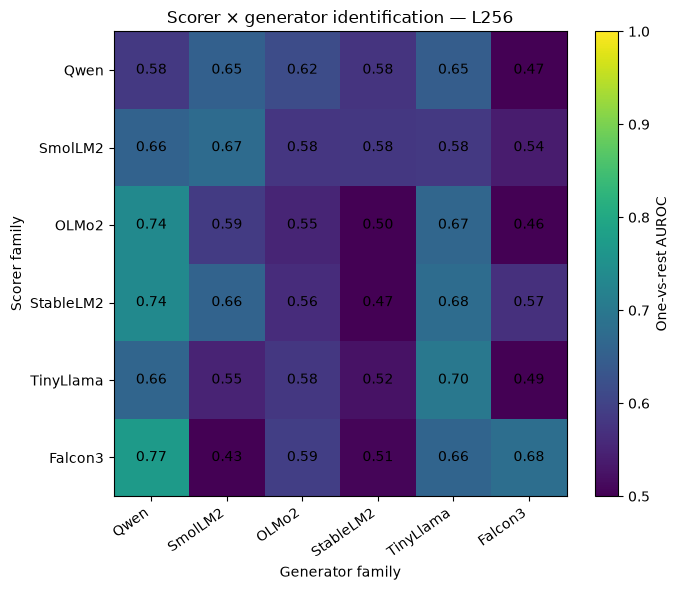

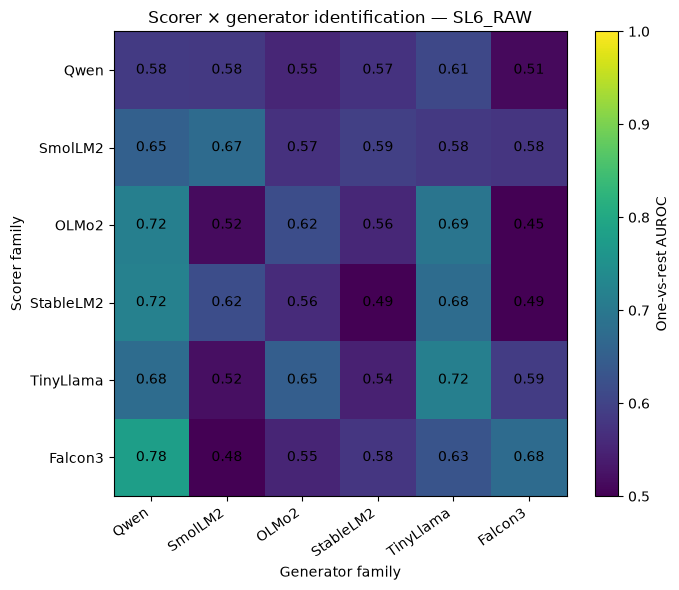

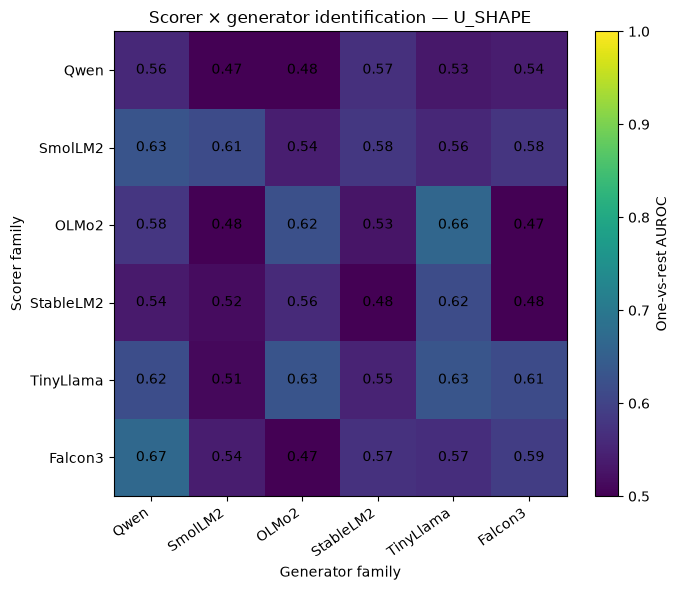

In [17]:

def plot_matrix(
    matrix,
    title,
    cbar_label,
    filename,
    vmin=None,
    vmax=None,
):
    fig, ax = plt.subplots(
        figsize=(7.0, 6.0)
    )

    im = ax.imshow(
        matrix.to_numpy(),
        aspect="auto",
        vmin=vmin,
        vmax=vmax,
    )

    ax.set_xticks(
        np.arange(len(matrix.columns))
    )
    ax.set_xticklabels(
        matrix.columns,
        rotation=35,
        ha="right",
    )

    ax.set_yticks(
        np.arange(len(matrix.index))
    )
    ax.set_yticklabels(
        matrix.index
    )

    ax.set_xlabel("Generator family")
    ax.set_ylabel("Scorer family")
    ax.set_title(title)

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(
                j,
                i,
                f"{matrix.iloc[i, j]:.2f}",
                ha="center",
                va="center",
            )

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)

    fig.tight_layout()

    fig.savefig(
        FIGURES / f"{filename}.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        FIGURES / f"{filename}.png",
        dpi=220,
        bbox_inches="tight",
    )

    plt.show()


for rep_name in [
    "L256",
    "SL6_RAW",
    "U_SHAPE",
]:
    matrix = (
        classification_summary[
            (classification_summary["representation"] == rep_name)
            &
            (classification_summary["generator_family"] != "__MACRO__")
        ]
        .pivot(
            index="scorer_family",
            columns="generator_family",
            values="mean",
        )
        .reindex(
            index=FAMILY_ORDER,
            columns=FAMILY_ORDER,
        )
    )

    plot_matrix(
        matrix,
        title=(
            "Scorer × generator identification — "
            + rep_name
        ),
        cbar_label="One-vs-rest AUROC",
        filename=(
            "sxg23_identification_"
            + rep_name.lower()
        ),
        vmin=0.5,
        vmax=1.0,
    )


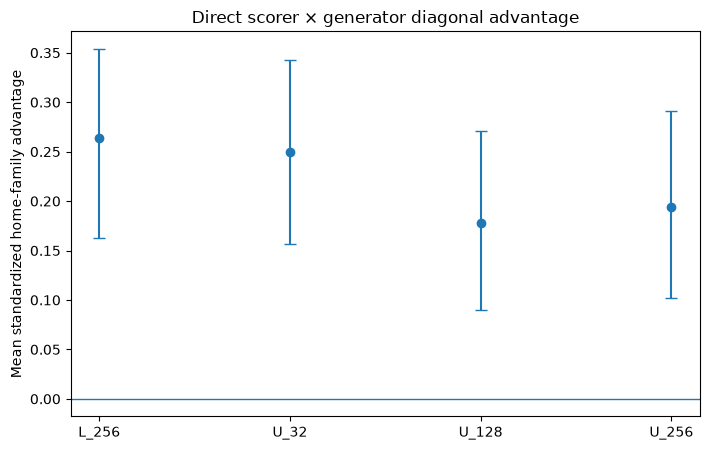

In [18]:

# Scalar diagonal-advantage figure.

q = diag_summary[
    diag_summary["generator_family"] == "__MEAN__"
].set_index("metric")

metrics = [
    "L_256",
    "U_32",
    "U_128",
    "U_256",
]

fig, ax = plt.subplots(
    figsize=(7.2, 4.6)
)

x = np.arange(len(metrics))
y = q.loc[metrics, "mean"].to_numpy()

lo = (
    y
    - q.loc[metrics, "ci_low"].to_numpy()
)
hi = (
    q.loc[metrics, "ci_high"].to_numpy()
    - y
)

ax.errorbar(
    x,
    y,
    yerr=np.vstack([lo, hi]),
    fmt="o",
    capsize=4,
)

ax.axhline(0, linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Mean standardized home-family advantage")
ax.set_title(
    "Direct scorer × generator diagonal advantage"
)

fig.tight_layout()

fig.savefig(
    FIGURES / "sxg23_scalar_diagonal_advantage.pdf",
    bbox_inches="tight",
)
fig.savefig(
    FIGURES / "sxg23_scalar_diagonal_advantage.png",
    dpi=220,
    bbox_inches="tight",
)

plt.show()


In [21]:
# ================================================================
# FAST exact 6! scorer <-> generator family-label permutation test
# ================================================================

from itertools import permutations

FAMS = list(FAMILY_ORDER)
PERMS = list(permutations(range(len(FAMS))))

assert len(PERMS) == 720

fam_to_idx = {
    fam: i
    for i, fam in enumerate(FAMS)
}

prompt_ids = np.array(
    sorted(eligible_groups)
)

prompt_to_idx = {
    gid: i
    for i, gid in enumerate(prompt_ids)
}


def build_z_tensor(metric):
    """
    Returns tensor Z[prompt, scorer, generator].
    """

    q = z_scores[
        z_scores["metric"] == metric
    ]

    Z = np.full(
        (
            len(prompt_ids),
            len(FAMS),
            len(FAMS),
        ),
        np.nan,
        dtype=float,
    )

    for r in q.itertuples(index=False):
        p = prompt_to_idx[str(r.group_id)]
        s = fam_to_idx[r.scorer_family]
        g = fam_to_idx[r.generator_family]

        Z[p, s, g] = r.z

    assert np.isfinite(Z).all()

    return Z


def mapping_statistic_fast(
    Z,
    perm,
    reverse_sign=False,
):
    """
    perm[g] = scorer index treated as the matched scorer
    for generator g.

    Returns mean diagonal advantage across prompts and generators.
    """

    P, S, G = Z.shape

    # home[p, g]
    home = np.stack(
        [
            Z[:, perm[g], g]
            for g in range(G)
        ],
        axis=1,
    )

    # Sum over every scorer for each prompt/generator.
    total = Z.sum(axis=1)

    # Mean over the other S-1 scorers.
    off = (
        total - home
    ) / (S - 1)

    diff = home - off

    if reverse_sign:
        diff = -diff

    return diff.mean()


scalar_test_rows = []
scalar_null_rows = []

for metric in [
    "L_256",
    "U_32",
    "U_128",
    "U_256",
]:
    Z = build_z_tensor(metric)

    stats = np.array([
        mapping_statistic_fast(
            Z,
            perm,
            reverse_sign=metric.startswith("L_"),
        )
        for perm in PERMS
    ])

    identity = tuple(
        range(len(FAMS))
    )

    identity_idx = PERMS.index(
        identity
    )

    observed = stats[
        identity_idx
    ]

    # Exact one-sided permutation p-value.
    p_exact = np.mean(
        stats >= observed
    )

    rank = int(
        1
        + np.sum(
            stats > observed
        )
    )

    scalar_test_rows.append({
        "metric": metric,
        "observed": observed,
        "null_mean": stats.mean(),
        "null_sd": stats.std(ddof=1),
        "null_min": stats.min(),
        "null_max": stats.max(),
        "identity_rank_of_720": rank,
        "p_exact_one_sided": p_exact,
    })

    scalar_null_rows.extend({
        "metric": metric,
        "perm_idx": i,
        "is_identity": i == identity_idx,
        "statistic": stat,
    } for i, stat in enumerate(stats))


scalar_perm_summary = pd.DataFrame(
    scalar_test_rows
)

scalar_perm_null = pd.DataFrame(
    scalar_null_rows
)

scalar_perm_summary.to_csv(
    RESULTS / "sxg23_scalar_exact_family_permutation_summary.csv",
    index=False,
)

scalar_perm_null.to_csv(
    RESULTS / "sxg23_scalar_exact_family_permutation_null.csv",
    index=False,
)

display(
    scalar_perm_summary
)

,metric,observed,null_mean,null_sd,null_min,null_max,identity_rank_of_720,p_exact_one_sided
0,L_256,0.264717,3.700743e-18,0.078469,-0.193663,0.264717,1,0.001389
1,U_32,0.250354,2.467162e-18,0.086471,-0.211295,0.250354,1,0.001389
2,U_128,0.178292,-9.868649e-18,0.068716,-0.172052,0.218563,8,0.011111
3,U_256,0.194771,0.000000e+00,0.068614,-0.177511,0.224101,4,0.005556


In [24]:
# ================================================================
# FAST exact family-mapping test for generator-identification AUROC
# ================================================================

classification_perm_rows = []
classification_perm_null_rows = []

identity = tuple(range(len(FAMS)))
identity_idx = PERMS.index(identity)

for representation in REPRESENTATIONS:

    # Rows = scorer family
    # Columns = generator family
    mat_df = (
        classification_summary[
            (classification_summary["representation"] == representation)
            &
            (
                classification_summary["generator_family"]
                != "__MACRO__"
            )
        ]
        .pivot(
            index="scorer_family",
            columns="generator_family",
            values="mean",
        )
        .reindex(
            index=FAMS,
            columns=FAMS,
        )
    )

    M = mat_df.to_numpy(dtype=float)

    assert M.shape == (
        len(FAMS),
        len(FAMS),
    )
    assert np.isfinite(M).all()

    # column_sum[g] = sum of AUROCs across scorers
    # for generator g.
    column_sum = M.sum(axis=0)

    stats = []

    for perm in PERMS:
        # perm[g] gives the scorer row treated as the
        # "matching" scorer for generator column g.
        home = np.array([
            M[perm[g], g]
            for g in range(len(FAMS))
        ])

        off = (
            column_sum - home
        ) / (len(FAMS) - 1)

        d = home - off

        stats.append(
            d.mean()
        )

    stats = np.asarray(stats)

    observed = stats[identity_idx]

    p_exact = np.mean(
        stats >= observed
    )

    rank = int(
        1 + np.sum(
            stats > observed
        )
    )

    classification_perm_rows.append({
        "representation": representation,
        "observed": observed,
        "null_mean": stats.mean(),
        "null_sd": stats.std(ddof=1),
        "null_min": stats.min(),
        "null_max": stats.max(),
        "identity_rank_of_720": rank,
        "p_exact_one_sided": p_exact,
    })

    classification_perm_null_rows.extend({
        "representation": representation,
        "perm_idx": i,
        "is_identity": i == identity_idx,
        "statistic": stat,
    } for i, stat in enumerate(stats))


classification_perm_summary = pd.DataFrame(
    classification_perm_rows
)

classification_perm_null = pd.DataFrame(
    classification_perm_null_rows
)

classification_perm_summary.to_csv(
    RESULTS
    / "sxg23_identification_exact_family_permutation_summary.csv",
    index=False,
)

classification_perm_null.to_csv(
    RESULTS
    / "sxg23_identification_exact_family_permutation_null.csv",
    index=False,
)

display(
    classification_perm_summary
)

,representation,observed,null_mean,null_sd,null_min,null_max,identity_rank_of_720,p_exact_one_sided
0,L256,0.015428,-3.330669e-17,0.030549,-0.095016,0.078164,240,0.333333
1,SL6_RAW,0.032600,-6.167906e-18,0.028258,-0.082706,0.078447,100,0.138889
2,U_SHAPE,0.027819,2.312965e-17,0.022683,-0.061042,0.069931,81,0.112500


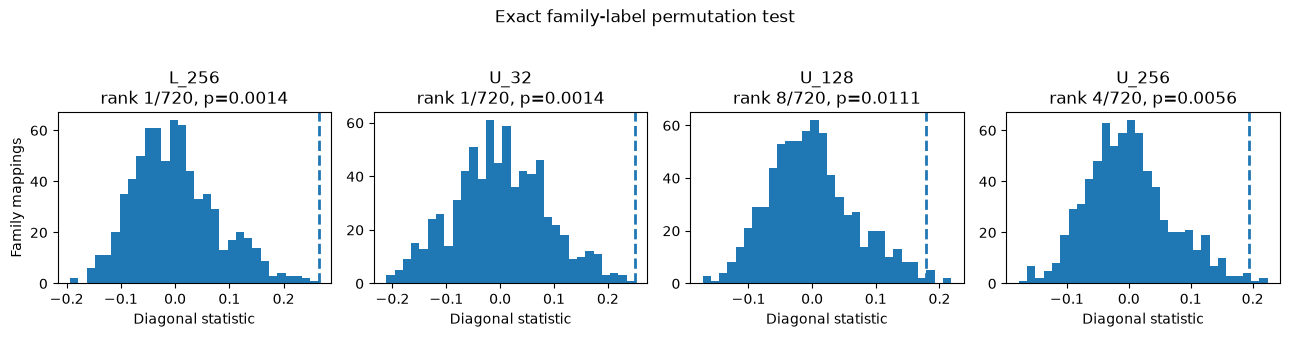

In [25]:
fig, axes = plt.subplots(
    1,
    4,
    figsize=(13, 3.2),
)

for ax, metric in zip(
    axes,
    ["L_256", "U_32", "U_128", "U_256"],
):
    q = scalar_perm_null[
        scalar_perm_null["metric"] == metric
    ]

    observed = q.loc[
        q["is_identity"],
        "statistic",
    ].iloc[0]

    ax.hist(
        q["statistic"],
        bins=30,
    )

    ax.axvline(
        observed,
        linestyle="--",
        linewidth=2,
    )

    row = scalar_perm_summary[
        scalar_perm_summary["metric"] == metric
    ].iloc[0]

    ax.set_title(
        f"{metric}\n"
        f"rank {row.identity_rank_of_720}/720, "
        f"p={row.p_exact_one_sided:.4f}"
    )

    ax.set_xlabel(
        "Diagonal statistic"
    )

axes[0].set_ylabel(
    "Family mappings"
)

fig.suptitle(
    "Exact family-label permutation test",
    y=1.04,
)

fig.tight_layout()

fig.savefig(
    FIGURES / "sxg23_exact_family_permutation.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURES / "sxg23_exact_family_permutation.png",
    dpi=220,
    bbox_inches="tight",
)

plt.show()

In [26]:
# Exact 6! permutation test on tokenizer-efficiency affinity.

tok_mean = (
    token_counts
    .groupby(
        ["scorer_family", "generator_family"]
    )["tokens_per_1k_chars"]
    .mean()
    .unstack()
    .reindex(
        index=FAMS,
        columns=FAMS,
    )
)

T = tok_mean.to_numpy(dtype=float)

# Within each scorer, standardize across generator families.
Tz = (
    T - T.mean(axis=1, keepdims=True)
) / T.std(axis=1, keepdims=True, ddof=1)

column_sum = Tz.sum(axis=0)

stats = []

for perm in PERMS:
    home = np.array([
        Tz[perm[g], g]
        for g in range(len(FAMS))
    ])

    off = (
        column_sum - home
    ) / (len(FAMS) - 1)

    # Fewer tokens / character = tokenizer-efficiency advantage.
    stats.append(
        (-(home - off)).mean()
    )

stats = np.asarray(stats)

identity = tuple(range(len(FAMS)))
identity_idx = PERMS.index(identity)

observed = stats[identity_idx]

summary = pd.DataFrame([{
    "metric": "tokenizer_efficiency",
    "observed": observed,
    "null_mean": stats.mean(),
    "null_sd": stats.std(ddof=1),
    "null_min": stats.min(),
    "null_max": stats.max(),
    "identity_rank_of_720":
        int(1 + np.sum(stats > observed)),
    "p_exact_one_sided":
        np.mean(stats >= observed),
}])

display(summary)

summary.to_csv(
    RESULTS / "sxg23_tokenizer_exact_family_permutation_summary.csv",
    index=False,
)

,metric,observed,null_mean,null_sd,null_min,null_max,identity_rank_of_720,p_exact_one_sided
0,tokenizer_efficiency,0.010634,6.476301e-18,0.110741,-0.202227,0.273525,225,0.3125



# Decision framework

Do not decide the scientific story from the raw-loss heatmap alone.

## Outcome A — diagonal in raw loss only

\[
D_L>0,\qquad
D_U\approx0,\qquad
D_{\mathrm{U\text{-}shape}}\approx0.
\]

Interpretation: same-family predictive compatibility exists, but there is no evidence
that dependency organization is preferentially exposed by the corresponding scorer.
Tokenizer/pretraining lineage is a sufficient explanation.

## Outcome B — direct long-range \(U\) diagonal

\[
D_{U(128)}>0,\qquad
D_{U(256)}>0,
\]

especially if stronger than \(D_{U(32)}\).

Interpretation: home-family scorers extract unusually strong long-range predictive
benefit from their own family outputs.

## Outcome C — generator-identification diagonal in \(U\)-shape

\[
A_{g,g}
>
\frac{1}{S-1}\sum_{s\neq g}A_{s,g}.
\]

This is the strongest result:

> family-specific dependency fingerprints are preferentially visible to predictors from
> the corresponding model lineage.

## Outcome D — no diagonal but strong columns

If many scorers differentiate generator families but home scorers are not privileged,
then dependency fingerprints live primarily in the generated text and are broadly
readable across observation models.

## Outcome E — block structure

Clusters rather than a strict diagonal may reveal shared predictive geometry among
related architectures/tokenizers/training lineages. Treat such blocks descriptively
unless they were hypothesized in advance.

## Required tokenizer sanity check

If raw-loss diagonal enrichment tracks tokenizer-efficiency diagonal enrichment while
the \(U\)-based results do not, do not frame the raw-loss diagonal as a dependency
finding.



# Conclusion template

### Direct diagonal

- \(L_{256}\) standardized home advantage: [...]
- \(U(32)\): [...]
- \(U(128)\): [...]
- \(U(256)\): [...]
- tokenizer-efficiency diagonal: [...]

### Generator differentiation

- `L256` global diagonal AUROC advantage: [...]
- `SL6_RAW`: [...]
- `U_SHAPE`: [...]

### Family-specific \(U\)-shape diagonals

| Generator family | Home scorer AUROC | Mean non-home AUROC | Difference |
|---|---:|---:|---:|
| Qwen | ... | ... | ... |
| SmolLM2 | ... | ... | ... |
| OLMo2 | ... | ... | ... |
| StableLM2 | ... | ... | ... |
| TinyLlama | ... | ... | ... |
| Falcon3 | ... | ... | ... |

### Scientific conclusion

Choose the narrowest conclusion supported by the data:

1. same-family predictive fit only;
2. same-family context-response resonance;
3. same-family dependency fingerprint for generator differentiation;
4. broadly readable generator fingerprints without diagonal privilege;
5. scorer/generator block structure rather than identity.

Do not add more model families until this 6×6 matrix is interpreted.
